In [ ]:
# read and inspect the tinyshakespeare dataset
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [ ]:
print("length of dataset in characters:", len(text))

In [ ]:
# let's look at the first 1000 characters
print(text[:1000])

In [ ]:
# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)

In [ ]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

In [ ]:
# let's now encode the entire text dataset and store it as a torch.Tensor
import torch
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000]) # the first 1000 characters will look like this to GPT

In [ ]:
# Split the data into train and validation sets
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [ ]:
block_size = 8
train_data[:block_size+1]

In [ ]:
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

In [ ]:
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?

def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

In [ ]:
print(xb) # we want to feed this batch of input into the transformer

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):
    
    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)
        
    def forward(self, idx, targets=None):
        
        # idx and targets are both (B,T) tensors of integers
        logits = self.token_embedding_table(idx) # (B,T,C) - (Batch, Time, Channel)
        
        if targets is None: 
            loss = None
        else:
            # reshape logits, targets because of how pytorch works (expects B*T,C)
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
        
            loss = F.cross_entropy(logits, targets)
        
        return logits, loss
    
    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities 
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx
            
    
m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

idx = torch.zeros((1, 1), dtype=torch.long) # create a new idx ((B,T) tensor) that is just a single 0, to expand for sampling
print(decode(m.generate(idx, max_new_tokens=100)[0].tolist())) # expand that idx (0 -- new line char) with the BigramLanguageModel.generate() func

# now let's train the bigram model

In [ ]:
# create a PyTorch optimizer
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3) # uses AdamW instead of SGD which makemore did

In [ ]:
batch_size = 32
for steps in range(10000):
    
    # sample a batch of data
    xb, yb = get_batch('train')
    
    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    
print(loss.item())
    

In [ ]:
# sample again after training the bigram LM
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))

Now instead of a bigram (ch1, ch2) model, let's get the tokens to talk to each other to make better predictions of what comes next

Before writing our first self-attention block for processing these tokens,

### The mathematical trick in self-attention

In [ ]:
# consider the following toy example:

torch.manual_seed(1337)
B,T,C = 4,8,2 # batch, time, channels
x = torch.randn(B,T,C)
x.shape

In [ ]:
# We want x[b,t] = mean_{i<=t} x[b,i]
xbow = torch.zeros((B,T,C)) # x bag of words
for b in range(B):
    for t in range(T):
        xprev = x[b,:t+1] # (t,C)
        xbow[b,t] = torch.mean(xprev, 0)

In [ ]:
# Faster version, using triangular matrix mult trick to get avges
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x # (B, T, T) @ (B, T, C) ----> (B, T, C)
torch.allclose(xbow, xbow2)

In [ ]:
# Version 3: use Softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf')) # future cannot communicate with the past
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
print(torch.allclose(xbow, xbow3))
wei

In [ ]:
# Version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x) # (B, T, 16)
q = query(x) # (B, T, 16)
# now all tokens in parallel in the (B, T) have produced a key and query -- independently, no communication yet
# now: all the queries will dot product with all the keys
wei = q @ k.transpose(-2, -1) * head_size**-0.5 # (B,T,16) @ (B,16,T) ---> (B,T,T)
# wei now data-dependent, rather than uniform

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
#out = wei @ x

out.shape

In [ ]:
wei[0]

Self-attention solves the problem: how does a token get the relevant information from previous tokens in a data-dependent way? 

Each token emits 2 vectors:
- Query: what am I looking for?
- Key: what do I contain?

To get "affinities" between tokens is to dot product: my query @ all keys = wei

So if the query and key are aligned, they will interact to a high degree, and let the current token learn more about that specific token as opposed to other tokens in the sequence.

------

eg. 8th token: knows what contents it has and what position it's in. Based on that, it creates a query: hey, I'm looking for this kind of stuff. I'm a vowel, 8th position, I'm looking for any consonants at positions 0-4. 

All the nodes emit keys. Maybe one of the channels could be: I am a consonant, and I am in a position 0-4. That key would have a high number in that specific channel. So when the query and key dot product, they find each other and create a high affinity. And when they have a high affinity, then through the softmax, current token will end up aggregating a lot of its information into my position, so I'll get to learn a lot about it.

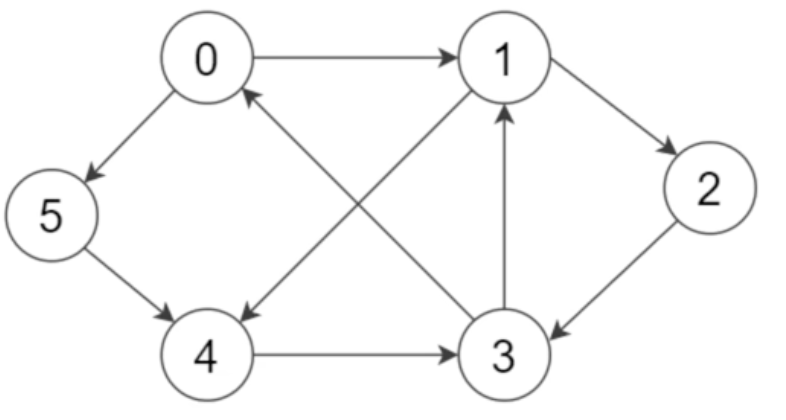

- **Attention is a communication mechanism.** You can think of it as a directed graph. Each node has a vector of information, and gets to aggregate information as a weighted sum of all the nodes that point to it.
    - num nodes/tokens is block size (8 in our case). The first node is only pointed to by itself. The second node is pointed to by the first node and itself, etc.
    - number of independent graphs is batch size.
- **Attention has no notion of space.** That's why we need to enforce a positional encoding for the tokens. Contrast to convolution.
- In our case, nodes only get information from previous nodes, never future nodes. This is not neccessary for the general case of attention. This is called a "decoder" attention block.
- Cases where all tokens communicate are called an "encoder" attention block. Implementationally this just means deleting the `tril` masking.


- These nodes are **self-attending** because the same source, `x` produces `keys`, `queries`, and `values`.
- It may be the case that `x` produces the `keys`, but `queries` and `values` come from separate encoder blocks -- a separate source:
- **Cross-attention** is an encoder-decoder architecture, used when there's a separate source of nodes we pool attention from into our nodes.
    - It is also the secret sauce for **multimodal** models like stable diffusion, which do text-to-image generation.
- **"Scaled"** attention additionally multiplies `wei` by `1/sqrt(head_size)` for some reason that I don't understand. To preserve variance and avoid saturation somehow. Basically to normalize it. This prevents softmax(wei...) from converging to one-hot vectors. Illustrated below.

In [ ]:
# Scaling the attention demo -- why we multiply wei by 1/sqrt(head_size)
print(torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]), dim=-1)) # this is ok, but...
print(torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])*8, dim=-1)) # when we sharpen the weights, softmax sharpens towards the max of the weight values (here 0.5)
# Basically softmax becomes too peak-y, and nodes end up aggregating information from just a single other node, rather than a nice distribution.

## Next: Multi-Head attention

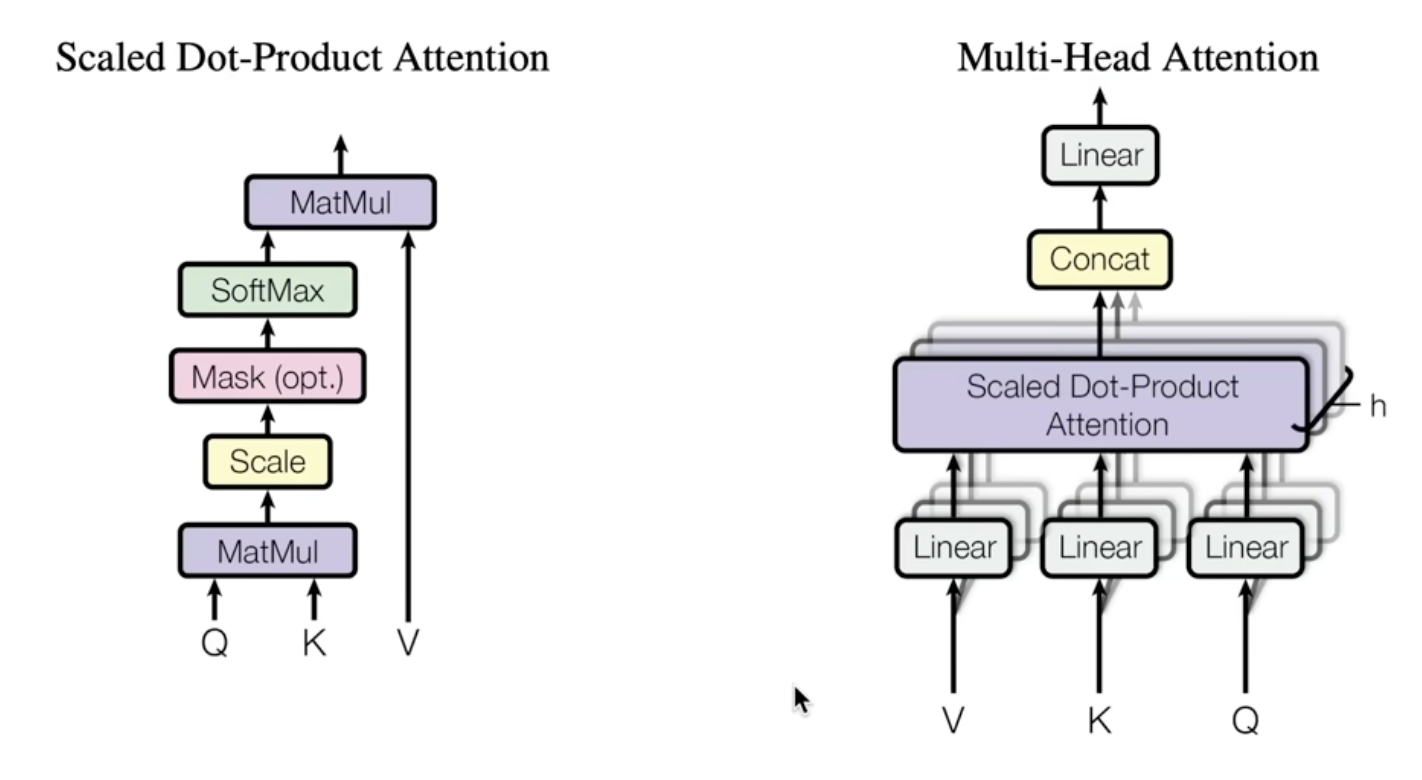

Really just multiple attentions in parallel.

## Transformer architecture

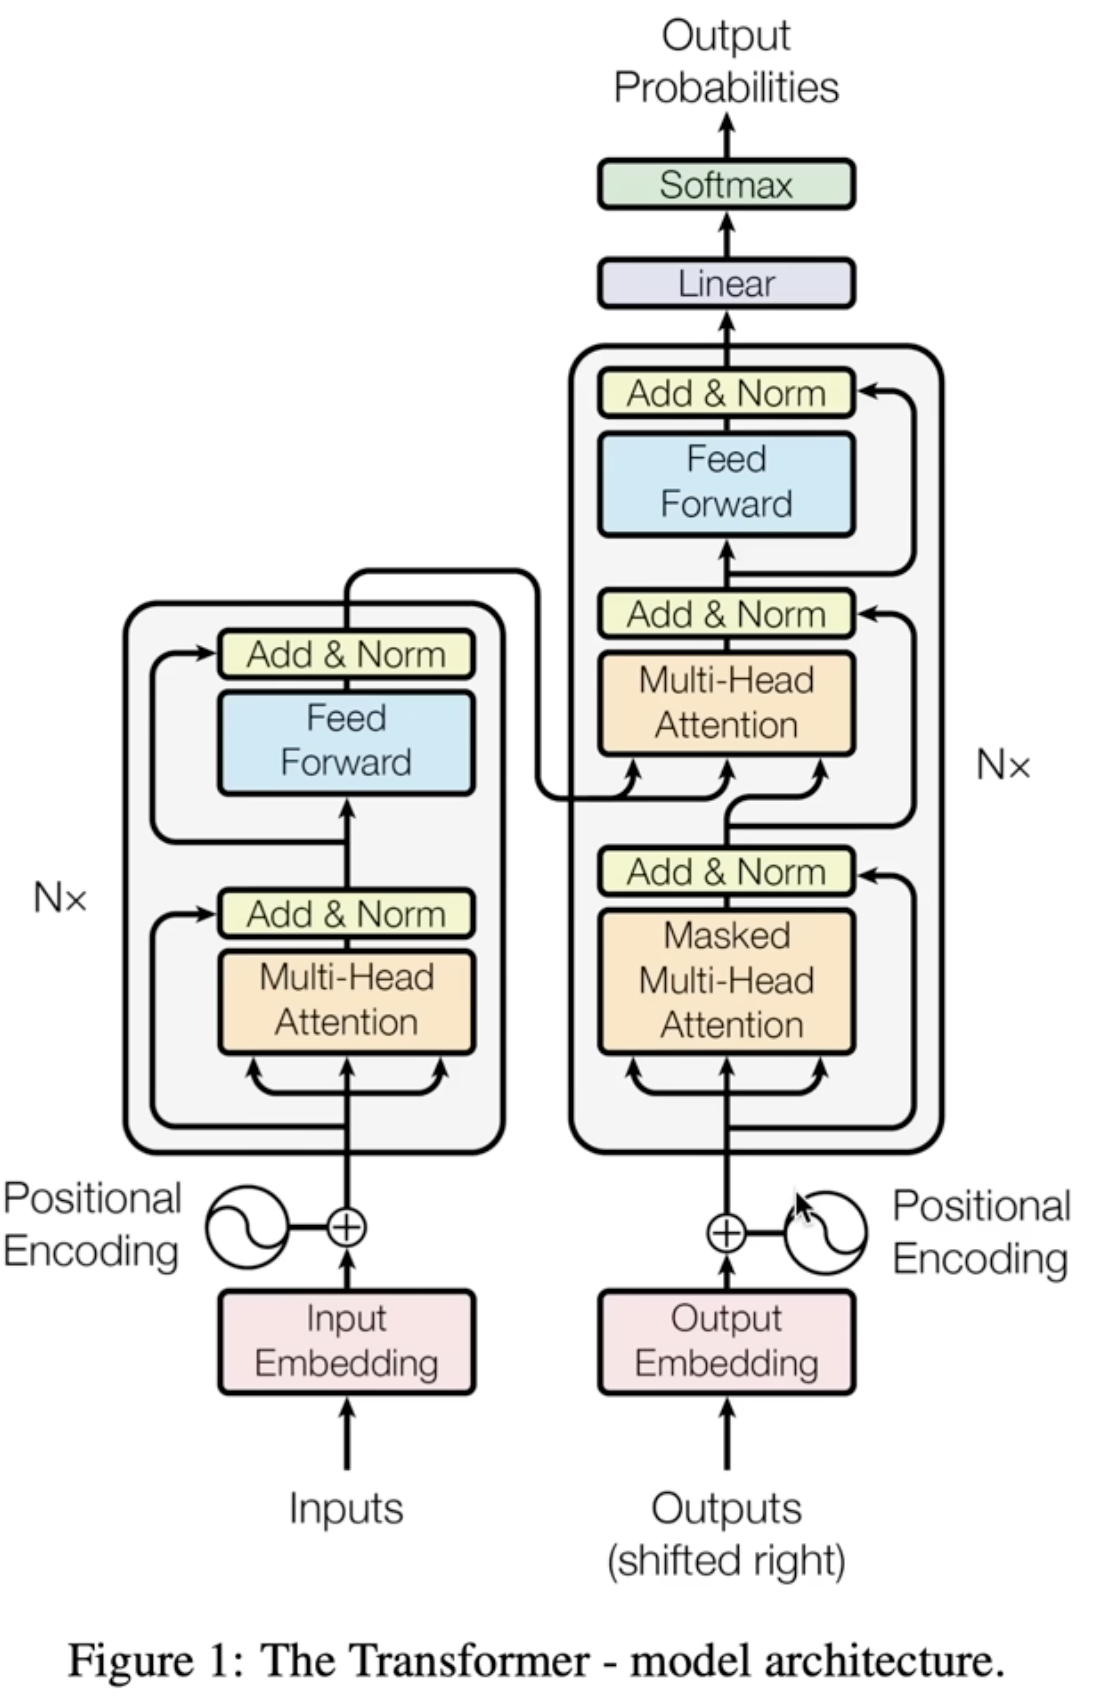

Left side is decoder, only for cross-attention architecture

## Residual / skip connections, visualized

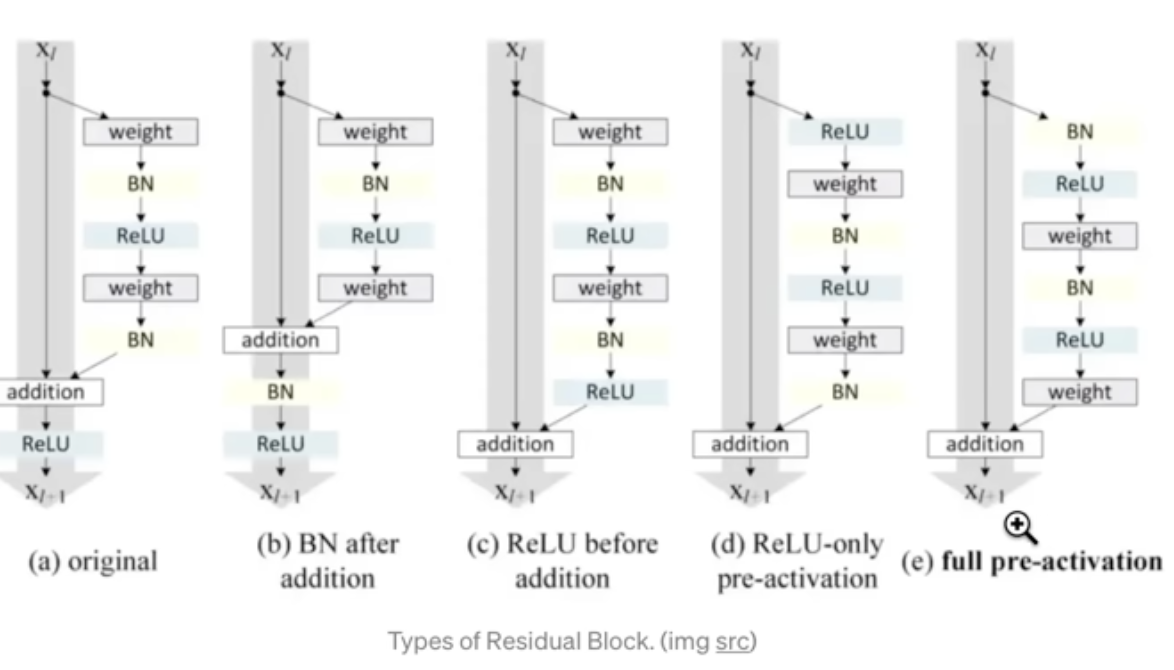

(from towardsdatascience.com)

This works because (recall from micrograd) addition distributes gradients equally to both of its terms. So basically the loss hops through every addition node up to the input (bottom-up) and also fork off during the forward pass to the residual blocks. 

The residual blocks are usually initialized in the beginning so that they don't really contribute to the residual pathway, but over optimization they start to contribute.